# Train YOLO on a Kaggle dataset

Detection training with **Ultralytics YOLO** + built-in augmentations
(brightness, zoom in/out, flips, mosaic, mixup, erasing, RandAugment).

**Before you run:** attach your dataset via **Add Input → Datasets**, then
update `RAW_IMAGES` and `RAW_LABELS` in the config cell below.

Enable GPU in the notebook settings (Settings → Accelerator → GPU T4 x2 or P100).

## 1. Install Ultralytics

In [1]:
# !pip install -q ultralytics

## 2. Explore your dataset

Run this to see what's under `/kaggle/input/`.

In [2]:
import os

# for root, dirs, files in os.walk("/kaggle/input"):
#     depth = root.replace("/kaggle/input", "").count(os.sep)
#     if depth > 3:
#         continue
#     print("  " * depth + os.path.basename(root) + "/")
#     if depth < 3:
#         for f in files[:5]:
#             print("  " * (depth + 1) + f)
#         if len(files) > 5:
#             print("  " * (depth + 1) + f"... ({len(files)} files total)")

## 3. Config

Edit the paths below to point at your dataset.
Expected layout: a folder of images and a matching folder of YOLO `.txt` labels
(one label file per image, same stem).

In [3]:
# ---- EDIT THESE ---------------------------------------------------
RAW_IMAGES = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\images"
RAW_LABELS = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\labels"
CLASS_NAMES = ["greenhouse"]   # your classes in order

TRAIN_RATIO = 0.8
MODEL_NAME  = "yolo11n.pt"     # n / s / m / l / x
EPOCHS      = 3
IMG_SIZE    = 640
BATCH       = 16
# -------------------------------------------------------------------

DATASET_DIR = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset"       # writable, gets the split
YAML_PATH   = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\data.yaml"
PROJECT_DIR = r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs"
RUN_NAME    = "exp"


## 4. Split the dataset (read from `/kaggle/input`, write to `/kaggle/working`)

In [4]:
# import random, shutil
# from pathlib import Path

# def split_dataset(images_dir, labels_dir, output_dir, train_ratio=0.8, seed=42):
#     random.seed(seed)
#     images_dir, labels_dir, output_dir = Path(images_dir), Path(labels_dir), Path(output_dir)

#     for split in ("train", "val"):
#         (output_dir / "images" / split).mkdir(parents=True, exist_ok=True)
#         (output_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

#     exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
#     images = [f for f in images_dir.iterdir() if f.suffix.lower() in exts]
#     if not images:
#         raise RuntimeError(f"No images found in {images_dir}")
#     random.shuffle(images)

#     cut = int(len(images) * train_ratio)
#     splits = {"train": images[:cut], "val": images[cut:]}

#     for split_name, files in splits.items():
#         for img in files:
#             shutil.copy2(img, output_dir / "images" / split_name / img.name)
#             lbl = labels_dir / f"{img.stem}.txt"
#             if lbl.exists():
#                 shutil.copy2(lbl, output_dir / "labels" / split_name / lbl.name)

#     print(f"train: {len(splits['train'])} | val: {len(splits['val'])}")

# split_dataset(RAW_IMAGES, RAW_LABELS, DATASET_DIR, TRAIN_RATIO)

## 5. Create `data.yaml`

In [5]:
# import yaml

# config = {
#     "path": DATASET_DIR,
#     "train": "images/train",
#     "val": "images/val",
#     "names": {i: n for i, n in enumerate(CLASS_NAMES)},
#     "nc": len(CLASS_NAMES),
# }
# with open(YAML_PATH, "w") as f:
#     yaml.dump(config, f, sort_keys=False)

# print(open(YAML_PATH).read())

## 6. Train

Augmentations are configured inline. Change them to taste:
- `hsv_v` → brightness
- `scale` → zoom in/out
- `mosaic`, `mixup`, `copy_paste`, `erasing` → advanced regularisation

In [6]:
from ultralytics import YOLO

model = YOLO(MODEL_NAME)

results = model.train(
    data=YAML_PATH,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,

    # ---- Colour / brightness -------------------------------------
    hsv_h=0.015,
    hsv_s=0.70,
    hsv_v=0.40,        # brightness

    # ---- Geometric (zoom lives here) -----------------------------
    degrees=10.0,
    translate=0.10,
    scale=0.5,         # zoom in/out ±50%
    shear=2.0,
    perspective=0.0001,

    # ---- Flips ---------------------------------------------------
    flipud=0.0,
    fliplr=0.5,

    # ---- Advanced ------------------------------------------------
    mosaic=1.0,
    mixup=0.15,
    copy_paste=0.10,
    auto_augment="randaugment",
    erasing=0.4,

    # ---- Checkpointing ------------------------------------------
    save=True,
    save_period=10,
    patience=30,

    # Kaggle GPU tip: use the second GPU too if you have T4 x2
    # device=[0, 1],
)

WARNING Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\alias\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None

c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:885: RuntimeWarning: Mean of empty slice
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/3         3G          0  9.884e-07          0          0        640: 100% ━━━━━━━━━━━━ 5292/5292 9.4it/s 9:200.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 662/662 10.8it/s 1:010.1sss
                   all      21184          0          0          0          0          0
WARNING no labels found in detect set, cannot compute metrics without labels


c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:885: RuntimeWarning: Mean of empty slice
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/3         3G          0   5.65e-08          0          0        640: 100% ━━━━━━━━━━━━ 5292/5292 9.4it/s 9:230.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 662/662 10.7it/s 1:020.2sss
                   all      21184          0          0          0          0          0
WARNING no labels found in detect set, cannot compute metrics without labels


c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:885: RuntimeWarning: Mean of empty slice
  i = smooth(f1_curve.mean(0), 0.1).argmax()  # max F1 index
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(



3 epochs completed in 0.524 hours.
Optimizer stripped from C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp\weights\last.pt, 5.5MB
Optimizer stripped from C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp\weights\best.pt, 5.5MB

Validating C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp\weights\best.pt...
Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 662/662 11.5it/s 57.8s0.1ss


c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:700: RuntimeWarning: Mean of empty slice
  ax.plot(px, py.mean(1), linewidth=3, color="blue", label=f"all classes {ap[:, 0].mean():.3f} mAP@0.5")
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:747: RuntimeWarning: Mean of empty slice
  y = smooth(py.mean(0), 0.1)
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\ultralytics\utils\metrics.py:747: RuntimeWarning: Mean of empty slice
  y = smooth(py.mean(0), 0.1)
c:\Users\alias\Documents\UNI\Thesis\.venv\Lib\site-packages\numpy\_core\_methods.py:134: Runtim

                   all      21184          0          0          0          0          0
WARNING no labels found in detect set, cannot compute metrics without labels
Speed: 0.1ms preprocess, 2.3ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp


## 7. Locate the best model (auto-saved by Ultralytics)

In [7]:
from pathlib import Path
import shutil

best = Path(PROJECT_DIR) / RUN_NAME / "weights" / "best.pt"
last = Path(PROJECT_DIR) / RUN_NAME / "weights" / "last.pt"
print("best:", best, "exists:", best.exists())
print("last:", last, "exists:", last.exists())

# Copy the best weights to /kaggle/working root for easy download
if best.exists():
    shutil.copy2(best, r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\best.pt")
    print(r"→ copied to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\best.pt")

best: C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp\weights\best.pt exists: True
last: C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\runs\exp\weights\last.pt exists: True
→ copied to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\best.pt


## 8. Quick sanity check on val images


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\images\val\GH_row_Kh_5_4765.jpg: 640x640 (no detections), 6.2ms
Speed: 6.3ms preprocess, 6.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\preds


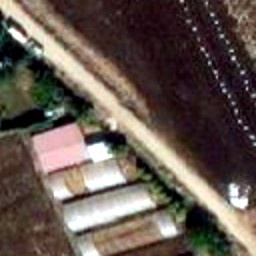


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\images\val\GH_row_Kh_8_43757.jpg: 640x640 (no detections), 6.0ms
Speed: 1.7ms preprocess, 6.0ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\preds


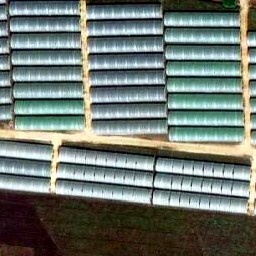


image 1/1 C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\yolo_dataset\images\val\GH_row_Kh_1_7140.jpg: 640x640 (no detections), 5.8ms
Speed: 1.8ms preprocess, 5.8ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\preds


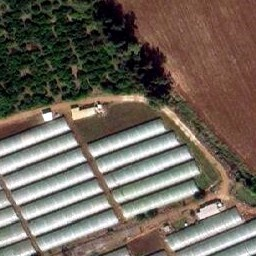

In [8]:
from ultralytics import YOLO
from IPython.display import Image, display
import glob, random

model = YOLO(r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models\best.pt")
val_imgs = glob.glob(f"{DATASET_DIR}/images/val/*")
sample = random.sample(val_imgs, min(3, len(val_imgs)))

for p in sample:
    r = model.predict(p, save=True, project=r"C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\models", name="preds", exist_ok=True)
    display(Image(filename=r[0].save_dir + "/" + Path(p).name))